## Original Setup

In [1]:
import nltk
from nltk.corpus import brown

nltk.download('brown')
nltk.download('universal_tagset')

corpus = brown.tagged_sents(tagset='universal')
print("Corpus length:", len(corpus))

[nltk_data] Downloading package brown to C:\Users\Anupam
[nltk_data]     Tiwari\AppData\Roaming\nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package universal_tagset to C:\Users\Anupam
[nltk_data]     Tiwari\AppData\Roaming\nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!


Corpus length: 57340


In [2]:
inputs = []
targets = []

for sentence_tag_pairs in corpus:
    tokens = []
    target = []
    for token, tag in sentence_tag_pairs:
        tokens.append(token)
        target.append(tag)
    inputs.append(tokens)
    targets.append(target)

In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Dense, Input, Bidirectional, LSTM, GRU, SimpleRNN, Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.models import Model
from tensorflow.keras.losses import SparseCategoricalCrossentropy

In [4]:
train_inputs, test_inputs, train_targets, test_targets = train_test_split(
    inputs, targets, test_size=0.3, random_state=42
)

In [5]:
# Convert sentences to sequences
MAX_VOCAB_SIZE = None
should_lowercase = False

word_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    lower=should_lowercase,
    oov_token='UNK',
)
word_tokenizer.fit_on_texts(train_inputs)

train_inputs_int = word_tokenizer.texts_to_sequences(train_inputs)
test_inputs_int = word_tokenizer.texts_to_sequences(test_inputs)

word2idx = word_tokenizer.word_index
V = len(word2idx)
print('Found %s unique tokens.' % V)

Found 47617 unique tokens.


In [6]:
def flatten(list_of_lists):
    return [val for sublist in list_of_lists for val in sublist]

In [7]:
# Convert targets to sequences
tag_tokenizer = Tokenizer()
tag_tokenizer.fit_on_texts(train_targets)

train_targets_int = tag_tokenizer.texts_to_sequences(train_targets)
test_targets_int = tag_tokenizer.texts_to_sequences(test_targets)

train_targets_int_unpadded = train_targets_int
test_targets_int_unpadded = test_targets_int

K = len(tag_tokenizer.word_index) + 1   # +1 because tokenizer starts from 1
print("Number of tags (K):", K)

Number of tags (K): 13


In [8]:
# Find max length
maxlen_train = max(len(sent) for sent in train_inputs)
maxlen_test = max(len(sent) for sent in test_inputs)
T = max(maxlen_train, maxlen_test)
print("Max sequence length T:", T)

Max sequence length T: 180


In [9]:
# Pad sequences
train_inputs_int = pad_sequences(train_inputs_int, maxlen=T)
test_inputs_int = pad_sequences(test_inputs_int, maxlen=T)

train_targets_int = pad_sequences(train_targets_int, maxlen=T)
test_targets_int = pad_sequences(test_targets_int, maxlen=T)

print("Train inputs shape:", train_inputs_int.shape)
print("Test inputs shape:", test_inputs_int.shape)

Train inputs shape: (40138, 180)
Test inputs shape: (17202, 180)


---
# Exercise #1 Solution

Will try different architectures:
1. LSTM (original)
2. GRU
3. SimpleRNN
4. Stacked LSTM (2 layers)
5. CNN-based model

In [10]:
def create_model(cell_type='LSTM', units=64, num_layers=1):
    i = Input(shape=(T,))
    x = Embedding(V + 1, 32)(i)   # +1 for padding/OOV handling

    if cell_type == 'LSTM':
        for _ in range(num_layers - 1):
            x = Bidirectional(LSTM(units, return_sequences=True))(x)
        x = Bidirectional(LSTM(units, return_sequences=True))(x)
    elif cell_type == 'GRU':
        for _ in range(num_layers - 1):
            x = Bidirectional(GRU(units, return_sequences=True))(x)
        x = Bidirectional(GRU(units, return_sequences=True))(x)
    elif cell_type == 'SimpleRNN':
        for _ in range(num_layers - 1):
            x = Bidirectional(SimpleRNN(units, return_sequences=True))(x)
        x = Bidirectional(SimpleRNN(units, return_sequences=True))(x)

    x = Dense(K, activation='softmax')(x)
    model = Model(i, x)
    model.compile(
        loss=SparseCategoricalCrossentropy(),
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

In [11]:
# 1. LSTM Model
print("Training LSTM...")
model_lstm = create_model('LSTM', units=64, num_layers=1)
r_lstm = model_lstm.fit(
    train_inputs_int, train_targets_int,
    epochs=5,
    validation_data=(test_inputs_int, test_targets_int),
    verbose=1
)

Training LSTM...
Epoch 1/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 122s 93ms/step - accuracy: 0.9758 - loss: 0.0841 - val_accuracy: 0.9956 - val_loss: 0.0148
Epoch 2/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 115s 92ms/step - accuracy: 0.9970 - loss: 0.0100 - val_accuracy: 0.9968 - val_loss: 0.0103
Epoch 3/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 116s 93ms/step - accuracy: 0.9981 - loss: 0.0060 - val_accuracy: 0.9970 - val_loss: 0.0094
Epoch 4/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 130s 103ms/step - accuracy: 0.9986 - loss: 0.0045 - val_accuracy: 0.9971 - val_loss: 0.0094
Epoch 5/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 127s 101ms/step - accuracy: 0.9989 - loss: 0.0035 - val_accuracy: 0.9970 - val_loss: 0.0100


In [12]:
# 2. GRU Model
print("Training GRU...")
model_gru = create_model('GRU', units=64, num_layers=1)
r_gru = model_gru.fit(
    train_inputs_int, train_targets_int,
    epochs=5,
    validation_data=(test_inputs_int, test_targets_int),
    verbose=1
)

Training GRU...
Epoch 1/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 132s 101ms/step - accuracy: 0.9831 - loss: 0.0632 - val_accuracy: 0.9960 - val_loss: 0.0128
Epoch 2/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 127s 101ms/step - accuracy: 0.9974 - loss: 0.0085 - val_accuracy: 0.9968 - val_loss: 0.0098
Epoch 3/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 131s 104ms/step - accuracy: 0.9983 - loss: 0.0052 - val_accuracy: 0.9971 - val_loss: 0.0092
Epoch 4/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 130s 103ms/step - accuracy: 0.9987 - loss: 0.0039 - val_accuracy: 0.9971 - val_loss: 0.0094
Epoch 5/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 129s 103ms/step - accuracy: 0.9990 - loss: 0.0031 - val_accuracy: 0.9971 - val_loss: 0.0098


In [13]:
# 3. SimpleRNN Model
print("Training SimpleRNN...")
model_rnn = create_model('SimpleRNN', units=64, num_layers=1)
r_rnn = model_rnn.fit(
    train_inputs_int, train_targets_int,
    epochs=5,
    validation_data=(test_inputs_int, test_targets_int),
    verbose=1
)

Training SimpleRNN...
Epoch 1/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 80s 61ms/step - accuracy: 0.9808 - loss: 0.0691 - val_accuracy: 0.9956 - val_loss: 0.0145
Epoch 2/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 72s 57ms/step - accuracy: 0.9971 - loss: 0.0095 - val_accuracy: 0.9966 - val_loss: 0.0105
Epoch 3/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 72s 57ms/step - accuracy: 0.9983 - loss: 0.0055 - val_accuracy: 0.9969 - val_loss: 0.0098
Epoch 4/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 72s 57ms/step - accuracy: 0.9988 - loss: 0.0038 - val_accuracy: 0.9967 - val_loss: 0.0104
Epoch 5/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 802s 639ms/step - accuracy: 0.9992 - loss: 0.0027 - val_accuracy: 0.9967 - val_loss: 0.0113


In [14]:
# 4. Stacked LSTM (2 layers)
print("Training Stacked LSTM...")
model_stacked = create_model('LSTM', units=64, num_layers=2)
r_stacked = model_stacked.fit(
    train_inputs_int, train_targets_int,
    epochs=5,
    validation_data=(test_inputs_int, test_targets_int),
    verbose=1
)

Training Stacked LSTM...
Epoch 1/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 239s 185ms/step - accuracy: 0.9709 - loss: 0.0936 - val_accuracy: 0.9957 - val_loss: 0.0145
Epoch 2/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 242s 193ms/step - accuracy: 0.9970 - loss: 0.0098 - val_accuracy: 0.9967 - val_loss: 0.0108
Epoch 3/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 259s 206ms/step - accuracy: 0.9982 - loss: 0.0058 - val_accuracy: 0.9970 - val_loss: 0.0100
Epoch 4/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 282s 225ms/step - accuracy: 0.9987 - loss: 0.0043 - val_accuracy: 0.9970 - val_loss: 0.0102
Epoch 5/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 202s 161ms/step - accuracy: 0.9989 - loss: 0.0033 - val_accuracy: 0.9970 - val_loss: 0.0110


In [15]:
# 5. CNN Model for POS Tagging
print("Training CNN...")
i = Input(shape=(T,))
x = Embedding(V + 1, 32)(i)
x = Conv1D(128, 3, activation='relu', padding='same')(x)
x = Conv1D(64, 3, activation='relu', padding='same')(x)
x = Dense(K, activation='softmax')(x)

model_cnn = Model(i, x)
model_cnn.compile(
    loss=SparseCategoricalCrossentropy(),
    optimizer='adam',
    metrics=['accuracy']
)

r_cnn = model_cnn.fit(
    train_inputs_int, train_targets_int,
    epochs=5,
    validation_data=(test_inputs_int, test_targets_int),
    verbose=1
)

Training CNN...
Epoch 1/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 22s 16ms/step - accuracy: 0.9879 - loss: 0.0456 - val_accuracy: 0.9963 - val_loss: 0.0119
Epoch 2/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.9977 - loss: 0.0073 - val_accuracy: 0.9968 - val_loss: 0.0101
Epoch 3/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.9986 - loss: 0.0045 - val_accuracy: 0.9969 - val_loss: 0.0101
Epoch 4/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.9990 - loss: 0.0031 - val_accuracy: 0.9969 - val_loss: 0.0106
Epoch 5/5
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.9992 - loss: 0.0023 - val_accuracy: 0.9969 - val_loss: 0.0112


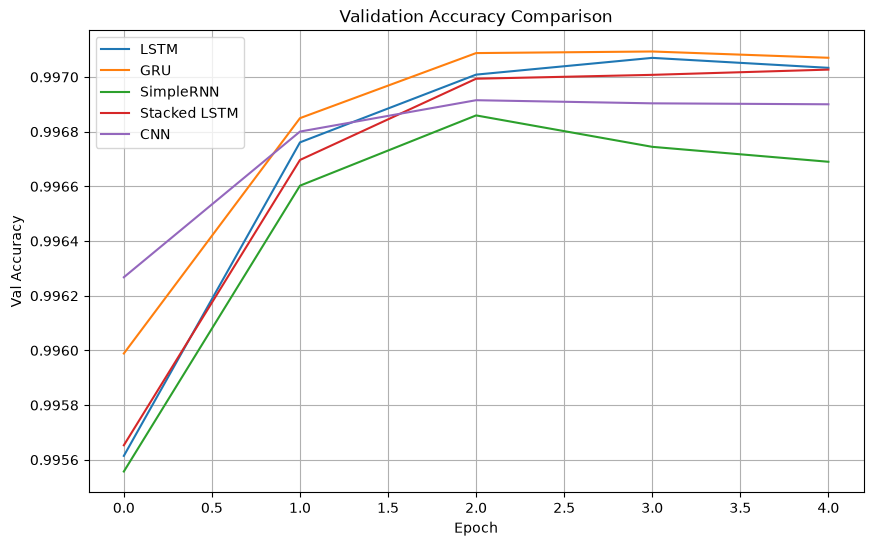

In [16]:
# Compare validation accuracy of all models
plt.figure(figsize=(10, 6))
plt.plot(r_lstm.history['val_accuracy'], label='LSTM')
plt.plot(r_gru.history['val_accuracy'], label='GRU')
plt.plot(r_rnn.history['val_accuracy'], label='SimpleRNN')
plt.plot(r_stacked.history['val_accuracy'], label='Stacked LSTM')
plt.plot(r_cnn.history['val_accuracy'], label='CNN')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Val Accuracy')
plt.legend()
plt.grid(True)
plt.show()

### Exercise #1 Observations:
- **LSTM / GRU** usually perform best for sequence tagging.
- **SimpleRNN** struggles more with longer dependencies.
- **Stacked LSTM** can improve performance but needs more training time.
- **CNN** is surprisingly strong for POS tagging because local context (surrounding words) is very important for determining the tag.

---
# Exercise #2 Solution – The Two Common Mistakes

Will intentionally introduce the two mistakes and show why accuracy becomes artificially high.

### Mistake #1: No OOV token → length mismatch / misalignment

In [17]:
# Create a tokenizer WITHOUT oov_token
bad_tokenizer = Tokenizer(num_words=None, lower=False)  # no oov_token!
bad_tokenizer.fit_on_texts(train_inputs)

train_inputs_bad = bad_tokenizer.texts_to_sequences(train_inputs)
test_inputs_bad = bad_tokenizer.texts_to_sequences(test_inputs)

# Check length mismatch
print("Example of length mismatch (Mistake #1):")
for i in range(5):
    print(f"Original tokens: {len(train_inputs[i])}, After tokenization: {len(train_inputs_bad[i])}")

Example of length mismatch (Mistake #1):
Original tokens: 31, After tokenization: 31
Original tokens: 30, After tokenization: 30
Original tokens: 8, After tokenization: 8
Original tokens: 15, After tokenization: 15
Original tokens: 20, After tokenization: 20


**Explanation of Mistake #1:**  
When there is no `oov_token`, unknown words are simply removed.  
This makes `len(input_sequence) != len(target_sequence)`.  
The tags no longer align with the words → model learns garbage.

### Mistake #2: Not ignoring padding in the loss

In [18]:
# Bad model: we do NOT mask the padding
i = Input(shape=(T,))
x = Embedding(V + 1, 32)(i)          # default mask_zero=False
x = Bidirectional(LSTM(64, return_sequences=True))(x)
x = Dense(K, activation='softmax')(x)

bad_model = Model(i, x)
bad_model.compile(
    loss=SparseCategoricalCrossentropy(),   # does NOT ignore padding
    optimizer='adam',
    metrics=['accuracy']
)

print("Training bad model (no padding mask)...")
r_bad = bad_model.fit(
    train_inputs_int, train_targets_int,
    epochs=3,
    validation_data=(test_inputs_int, test_targets_int),
    verbose=1
)

Training bad model (no padding mask)...
Epoch 1/3
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 90s 68ms/step - accuracy: 0.9756 - loss: 0.0842 - val_accuracy: 0.9954 - val_loss: 0.0152
Epoch 2/3
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 89s 71ms/step - accuracy: 0.9981 - loss: 0.0061 - val_accuracy: 0.9970 - val_loss: 0.0095


In [19]:
print("Bad model validation accuracy (includes padding):", r_bad.history['val_accuracy'][-1])

Bad model validation accuracy (includes padding): 0.996984601020813


### Why does the accuracy look so high (~99%)?

Because of **padding**.  
Most of the sequence is padding tokens (value 0).  
The model quickly learns to predict the padding tag correctly for all the padded positions.  
Since padding positions dominate the sequence, overall accuracy becomes extremely high even if the model is terrible at real words.

This is why we must either:
1. Use `mask_zero=True` in the Embedding layer, **or**
2. Pass `sample_weight` to ignore padding positions when computing loss/metrics.

### Correct way (for comparison)

In [20]:
# Correct model with mask_zero=True
i = Input(shape=(T,))
x = Embedding(V + 1, 32, mask_zero=True)(i)   # <-- important!
x = Bidirectional(LSTM(64, return_sequences=True))(x)
x = Dense(K, activation='softmax')(x)

good_model = Model(i, x)
good_model.compile(
    loss=SparseCategoricalCrossentropy(),
    optimizer='adam',
    metrics=['accuracy']
)

print("Training good model (with mask_zero=True)...")
r_good = good_model.fit(
    train_inputs_int, train_targets_int,
    epochs=3,
    validation_data=(test_inputs_int, test_targets_int),
    verbose=1
)

Training good model (with mask_zero=True)...
Epoch 1/3
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 127s 94ms/step - accuracy: 0.8808 - loss: 0.3864 - val_accuracy: 0.9671 - val_loss: 0.1051
Epoch 2/3
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 109s 86ms/step - accuracy: 0.9793 - loss: 0.0665 - val_accuracy: 0.9719 - val_loss: 0.0883
Epoch 3/3
1255/1255 ━━━━━━━━━━━━━━━━━━━━ 112s 89ms/step - accuracy: 0.9870 - loss: 0.0405 - val_accuracy: 0.9728 - val_loss: 0.0866


---
## Summary

### Exercise 1
- LSTM and GRU are strong baselines.
- CNNs also work surprisingly well for POS tagging.
- Stacking layers can help but increases training time.

### Exercise 2
- **Mistake 1**: Missing `oov_token` → sequences become misaligned.
- **Mistake 2**: Not masking padding → accuracy becomes artificially high because the model just learns to predict padding correctly.

**Always think about what the library is doing instead of blindly using default parameters.**